# LightGBM on TF-IDF

This notebook trains a LightGBM model on the same TF-IDF features and train/test split as the Logistic Regression baseline. A boosted model of 200 trees cannot be read directly, so we explain it with post-hoc methods.

The explanation steps follow the course's interpretation pipeline: global importance (PFI / TreeSHAP) → feature effects (PDP) → heterogeneity (ICE) → individual decisions (LIME / SHAP).

## 1.Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("punkt")
nltk.download("punkt_tab")

from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, recall_score, accuracy_score
)
from sklearn.inspection import PartialDependenceDisplay

from lime.lime_text import LimeTextExplainer
from lime.submodular_pick import SubmodularPick
import shap

from preprocessing import (
    preprocess_text, get_tfidf_features,
    get_train_test_split, select_top_k_terms, RANDOM_STATE
)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ADMIN\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv")
df[["title", "text", "label", "label_encoded"]].head()

,title,text,label,label_encoded
0,Foreign Democrat final.,more tax development both store agreement lawy...,real,0
1,To offer down resource great point.,probably guess western behind likely next inve...,fake,1
2,Himself church myself carry.,them identify forward present success risk sev...,fake,1
3,You unit its should.,phone which item yard Republican safe where po...,fake,1
4,Billion believe employee summer how.,wonder myself fact difficult course forget exa...,fake,1


## 3. Text Preprocessing

In [3]:
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
df[["full_text", "processed_text"]].head()

,full_text,processed_text
0,Foreign Democrat final. more tax development b...,foreign democrat final tax development store a...
1,To offer down resource great point. probably g...,offer resource great point probably guess west...
2,Himself church myself carry. them identify for...,church carry identify forward present success ...
3,You unit its should. phone which item yard Rep...,unit phone item yard republican safe police id...
4,Billion believe employee summer how. wonder my...,billion believe employee summer wonder fact di...


Quick check: compare one raw vs. processed example side by side.

In [4]:
print("RAW:\n", df["full_text"].iloc[0][:300])
print("\nPROCESSED:\n", df["processed_text"].iloc[0][:300])

RAW:
 Foreign Democrat final. more tax development both store agreement lawyer hear outside continue reach difference yeah figure your power fear identify there protect security great national nothing fast story why late nearly bit cost tough since question to power almost future young conference behind a

PROCESSED:
 foreign democrat final tax development store agreement lawyer hear outside continue reach difference yeah figure power fear identify protect security great national nothing fast story late nearly bit cost tough since question power almost future young conference behind ahead building teach million b


## 4. TF-IDF Vectorization

In [5]:
X, y, tfidf = get_tfidf_features(df)
feature_names = tfidf.get_feature_names_out()

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (20000, 867)


## 5. Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = get_train_test_split(X, y)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain class balance:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest class balance:\n", y_test.value_counts(normalize=True).round(3))

Train shape: (16000, 867)
Test shape: (4000, 867)

Train class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64

Test class balance:
 label_encoded
1    0.503
0    0.497
Name: proportion, dtype: float64


## 6. Train LightGBM

LightGBM builds trees one after another, each fixing the mistakes of the trees before it. We keep the trees small (depth 4, at most 15 leaves, at least 50 articles per leaf) and the learning rate low, so the model memorizes less of the training data and is quick to explain with TreeSHAP.

In [7]:
lgbm = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=4,
    min_child_samples=50,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)
lgbm.fit(X_train, y_train)
y_pred = lgbm.predict(X_test)

## 7. Validate Predictive Performance

In [8]:
print(classification_report(y_test, y_pred, target_names=["real", "fake"]))

recall_fake = recall_score(y_test, y_pred, pos_label=1)
accuracy = accuracy_score(y_test, y_pred)
train_recall = recall_score(y_train, lgbm.predict(X_train), pos_label=1)

print(f"Fake-class recall (test):  {recall_fake:.4f}")
print(f"Fake-class recall (train): {train_recall:.4f}   <- large gap vs test = overfitting")
print(f"Accuracy (test): {accuracy:.4f}")

from sklearn.metrics import roc_auc_score
auc = roc_auc_score(y_test, lgbm.predict_proba(X_test)[:, 1])
print(f"ROC AUC (test): {auc:.4f}")
print(f"Share of test articles predicted fake: {y_pred.mean():.3f}")

              precision    recall  f1-score   support

        real       0.51      0.50      0.50      1989
        fake       0.51      0.52      0.52      2011

    accuracy                           0.51      4000
   macro avg       0.51      0.51      0.51      4000
weighted avg       0.51      0.51      0.51      4000

Fake-class recall (test):  0.5191
Fake-class recall (train): 0.7768   <- large gap vs test = overfitting
Accuracy (test): 0.5088
ROC AUC (test): 0.5155
Share of test articles predicted fake: 0.510


LightGBM finds 52% of the fake articles (recall 0.5191) and is right 51% of the time it says fake, barely above the 50.3% share of fake articles in the test set. Accuracy (0.5088) and ROC AUC (0.5155) are both close to 0.5, meaning the model ranks fake articles above real ones barely better than a coin flip.

The model labels 51% of articles as fake, and its recall is almost the same number. So it catches fake articles at about the rate you would get by flagging half the articles at random.

Training recall is 0.7768 against 0.5191 on test, so even with small trees the model fits the training articles much better than new ones. Compared with the Logistic Regression baseline (0.5167), it catches only about 5 more fake articles.

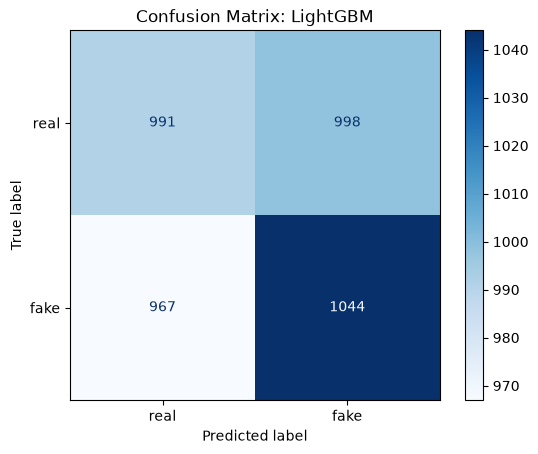

In [9]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["real", "fake"]).plot(cmap="Blues")
plt.title("Confusion Matrix: LightGBM")
plt.show()

- True Positive, correctly caught fake article: 1,044
- False Negative, fake article predicted as real: 967
- False Positive, real article predicted as fake: 998
- True Negative, correctly identified real article: 991

The four cells are almost equal, so the model is wrong about as often as it is right in both classes. It misses 967 fake articles (48%) and flags 998 real ones (50%).

For a trust-and-safety reviewer, this means 2,042 articles sent for checking, of which only 1,044 are fake. Half the reviewer's time goes to real articles, while almost half the fake ones are never flagged. It raises fewer false alarms than the baseline (998 vs 1,036), but the difference is small.

## 8. Top-K Terms and Multicollinearity Check

With 867 terms, inspecting every term is impractical: PDP and ICE would need hundreds of plots, and an 867 × 867 correlation matrix cannot be read. We therefore focus on the 30 terms most linked to the fake/real label (K = 30), ranked by a chi-squared score on the training data only.

Chi-squared measures how unevenly a term's weight is split between fake and real articles. A higher score means a stronger link to the label, but it does not show the direction. We use it because it does not depend on any model, so every notebook can share the same list. Since TF-IDF weights are not counts, the scores are used only for ranking, not as significance tests.

In [10]:
K = 30
top_idx, top_terms, top_scores = select_top_k_terms(X_train, y_train, feature_names, k=K, method="chi2")
pd.DataFrame({"term": top_terms, "chi2_score": top_scores}).head(7)

,term,chi2_score
0,economy,0.576492
1,particular,0.551777
2,significant,0.531097
3,model,0.517952
4,girl,0.503255
5,bring,0.501048
6,reflect,0.499708


The top seven terms (economy, particular, significant, model, girl, bring, reflect) are ordinary words, not sensational language. Their scores are low and close together (0.50 to 0.58), so no term stands out.

All 30 terms are used below, but tables and plots show only 7 at a time, since people can hold about 7 ± 2 items in working memory.

In [11]:
X_test_dense = X_test.toarray().astype(np.float32)

rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_test_dense.shape[0], size=500, replace=False)
X_sample = X_test_dense[sample_idx]          # 500-row sample for PDP/ICE and SHAP

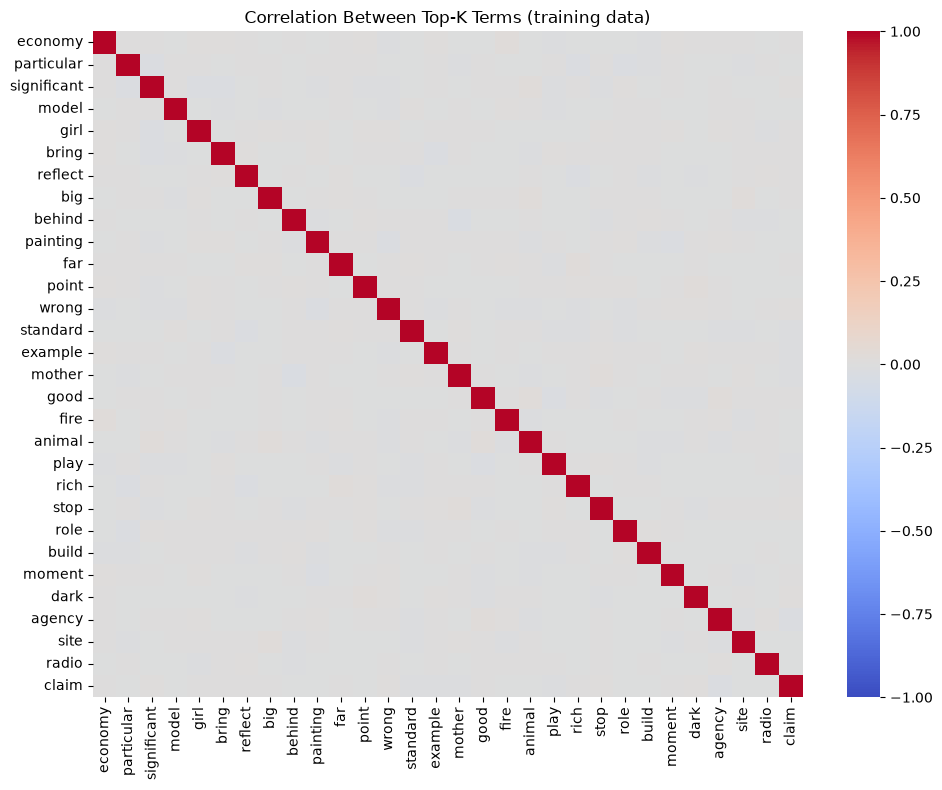

No pairs of terms with |correlation| > 0.5


In [12]:
X_train_topk = pd.DataFrame(X_train[:, top_idx].toarray(), columns=top_terms)
corr = X_train_topk.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Between Top-K Terms (training data)")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = pairs[pairs.abs() > 0.5]
if high_pairs.empty:
    print("No pairs of terms with |correlation| > 0.5")
else:
    print("Pairs with |correlation| > 0.5:")
    print(high_pairs.sort_values(key=abs, ascending=False))

The heatmap shows how strongly the weights of each pair of top terms move together. Apart from the diagonal, where each term is compared with itself, every cell is close to 0, and no pair goes above 0.5.

This matters for two methods. PFI can split importance between related terms, and PDP changes one term while holding the others fixed, which only gives realistic articles if the terms are not related. Since the top terms are close to independent, we use PDP rather than ALE. The check only covers the top 30 terms and linear relationships, so it does not rule out every dependence.

## 9. Global Importance (PFI and TreeSHAP)

### 9.1 Permutation Feature Importance (PFI)

Each of the 30 top terms is shuffled across the test articles, and we measure how much Fake-class recall drops, averaged over 5 repeats. A large drop means the model relies on that term to catch fake articles. A drop near zero means it barely matters.

In [13]:
def permutation_recall_drop(model, X_dense, y_true, col_indices, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = recall_score(y_true, model.predict(X_dense), pos_label=1)
    rows = []
    for col in col_indices:
        original = X_dense[:, col].copy()
        drops = []
        for _ in range(n_repeats):
            X_dense[:, col] = rng.permutation(original)
            drops.append(base - recall_score(y_true, model.predict(X_dense), pos_label=1))
        X_dense[:, col] = original
        rows.append((feature_names[col], np.mean(drops), np.std(drops)))
    result = pd.DataFrame(rows, columns=["term", "mean_recall_drop", "std"])
    return base, result.sort_values("mean_recall_drop", ascending=False)

base_recall, pfi_df = permutation_recall_drop(lgbm, X_test_dense, y_test, top_idx)
print(f"Recall before shuffling: {base_recall:.4f}")
pfi_df.head(7)

Recall before shuffling: 0.5191


,term,mean_recall_drop,std
28,radio,0.005172,0.002237
9,painting,0.003381,0.001062
1,particular,0.003182,0.003808
13,standard,0.002287,0.001850
23,build,0.001989,0.002290
22,role,0.001691,0.001622
24,moment,0.001492,0.000703


All drops are small. The largest, for radio, is 0.0052, about 10 of the 2,011 fake test articles. The smallest shown, for moment, is about 3 articles.

radio, painting and moment drop by a little more than twice their standard deviation. For particular and build the standard deviation is larger than the drop itself, and standard and role are only about one standard deviation above zero, so for these four the effect is less certain.

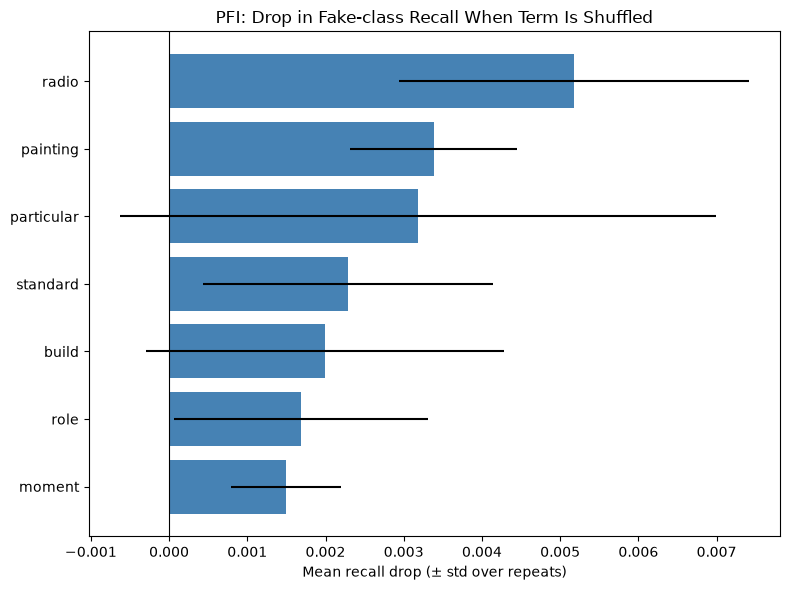

In [14]:
top_pfi = pfi_df.head(7).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_pfi["term"], top_pfi["mean_recall_drop"], xerr=top_pfi["std"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("PFI: Drop in Fake-class Recall When Term Is Shuffled")
plt.xlabel("Mean recall drop (± std over repeats)")
plt.tight_layout()
plt.show()

The error bars of particular and build cross zero, and those of standard and role only just clear it. The bars are wide compared with the gaps between them, so the order should not be read closely.

radio and painting have the largest drops, but they do not appear among SHAP's top terms below. The check below tests whether these drops are larger than chance.

#### Is PFI measuring anything?

As a check, we shuffle 30 random terms from outside the top 30. If their drops are as large as those of the top terms, the PFI ranking cannot be told apart from noise.

In [ ]:
rng_null = np.random.RandomState(RANDOM_STATE)
other_idx = rng_null.choice(np.setdiff1d(np.arange(len(feature_names)), top_idx), 30, replace=False)
_, pfi_null = permutation_recall_drop(lgbm, X_test_dense, y_test, other_idx)
print(pfi_null["mean_recall_drop"].describe())

count    30.000000
mean     -0.000474
std       0.000900
min      -0.002785
25%      -0.000970
50%      -0.000050
75%       0.000000
max       0.000696
Name: mean_recall_drop, dtype: float64


The 30 random terms barely matter. Their largest drop is 0.0007, and at least a quarter have a drop of exactly zero, probably because LightGBM never uses them. All seven top PFI terms drop recall by more than this (0.0015 to 0.0052), so their effects are small but real.

### 9.2 TreeSHAP (global view)

SHAP splits each prediction into a contribution from each term, starting from the model's average output. TreeSHAP calculates these values exactly for tree models. They are computed for the same 200 test articles as in the other notebooks and then averaged.

For LightGBM, SHAP values are in log-odds, not probability. Positive values push toward fake and negative values toward real. Near a probability of 0.5, a change of 0.1 in log-odds is about 2.5 percentage points.

In [16]:
explainer_shap = shap.TreeExplainer(lgbm)
X_shap = X_sample[:200]

sv = explainer_shap.shap_values(X_shap, check_additivity=False)

# SHAP's output format differs by version; extract values for the FAKE class (index 1)
if isinstance(sv, list):
    sv_fake = sv[1]
elif sv.ndim == 3:
    sv_fake = sv[:, :, 1]
else:
    sv_fake = sv

ev = explainer_shap.expected_value
base_value = ev[1] if np.ndim(ev) > 0 else ev
print("SHAP values shape:", sv_fake.shape)

SHAP values shape: (200, 867)


c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


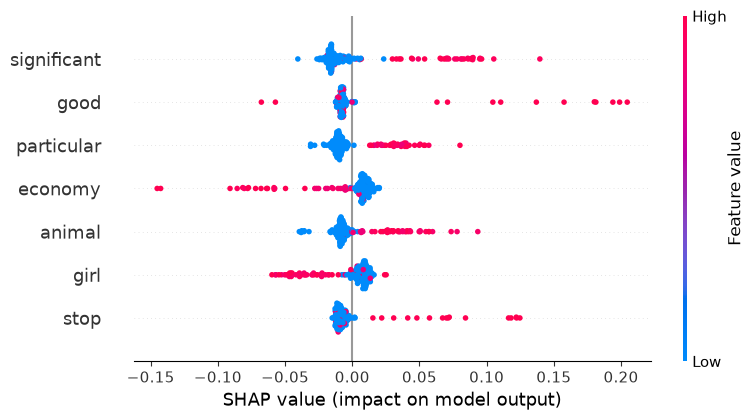

In [17]:
shap.summary_plot(sv_fake, X_shap, feature_names=list(feature_names), max_display=7)

In [18]:
shap_importance = pd.DataFrame({
    "term": feature_names,
    "mean_abs_shap": np.abs(sv_fake).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

shap_importance.head(7)

,term,mean_abs_shap
683,significant,0.022815
316,good,0.015762
528,particular,0.015752
220,economy,0.015062
36,animal,0.014345
311,girl,0.014034
736,stop,0.013791


Each dot is one article. Its position shows how much a term pushed the output toward fake (right) or real (left), and its color shows the term's weight: red for high, blue for low or absent.

Most dots are blue and near zero, since most articles don't contain a given term. The red dots carry the effect: significant, good, particular, animal and stop push toward fake, while economy and girl push toward real. good mostly pushes toward fake, but two articles go the other way.

The largest single push is about 0.2 log-odds (good), roughly 5 percentage points. On average, significant moves the output by 0.023 log-odds, about 0.6 percentage points, and the other six terms are close behind.

All seven directions match the baseline. PFI ranks the terms differently, with only particular in both top-seven lists. All seven of SHAP's terms are among the 30 that PFI tested, and the PFI check showed its drops are real, so the difference comes from what each method measures. SHAP measures how much a term moves the output on average, across all articles. PFI measures how much the model's ability to catch fake articles suffers when the term is shuffled. Terms like radio and painting move the output less on average, but they matter more for which fake articles get caught. Both methods agree that every effect is small.

## 10. Feature Effects (PDP)

PDP shows the model's average predicted probability of fake as one term's weight increases, so it shows which direction a term pushes and how strongly. Because the top terms are not correlated, we use PDP rather than ALE. The six terms with the highest chi-squared scores are plotted.

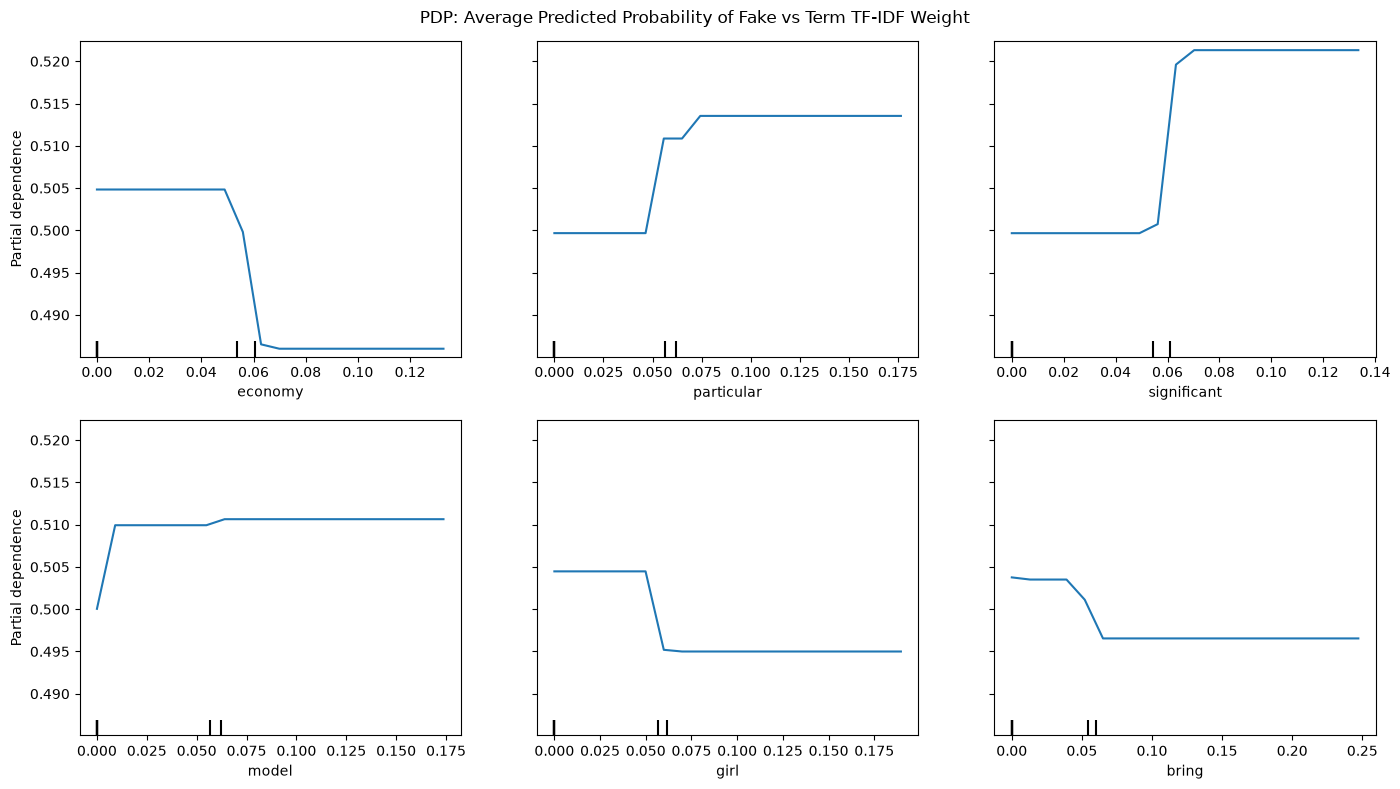

In [19]:
pdp_idx = list(top_idx[:6])

pdp_display = PartialDependenceDisplay.from_estimator(
    lgbm, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="average",
    grid_resolution=20,
    percentiles=(0, 1),       # TF-IDF is mostly zeros, so the default 5-95% range would collapse to a single value
    n_cols=3,
    random_state=RANDOM_STATE,
)
pdp_display.figure_.set_size_inches(14, 8)
pdp_display.figure_.suptitle("PDP: Average Predicted Probability of Fake vs Term TF-IDF Weight")
plt.tight_layout()
plt.show()

Each curve is a step: flat, a jump around a weight of 0.05, then flat again. A term is either absent (weight 0) or present at about 0.055 or more, so the step is the difference between containing the word and not. Weights in between never occur, so the exact position of the jump means nothing. This is why model jumps at 0.01: the trees placed its split somewhere in that empty gap.

particular, significant and model raise the probability of fake, and economy, girl and bring lower it. These directions match SHAP and the baseline.

The largest steps, for significant (0.500 to 0.521) and economy (0.505 to 0.486), are about 2 percentage points. particular moves about 1.4 points, model and girl about 1, and bring 0.7.

## 11. Heterogeneity (ICE)

ICE draws one line per article instead of only the average, showing whether a term affects every article the same way.

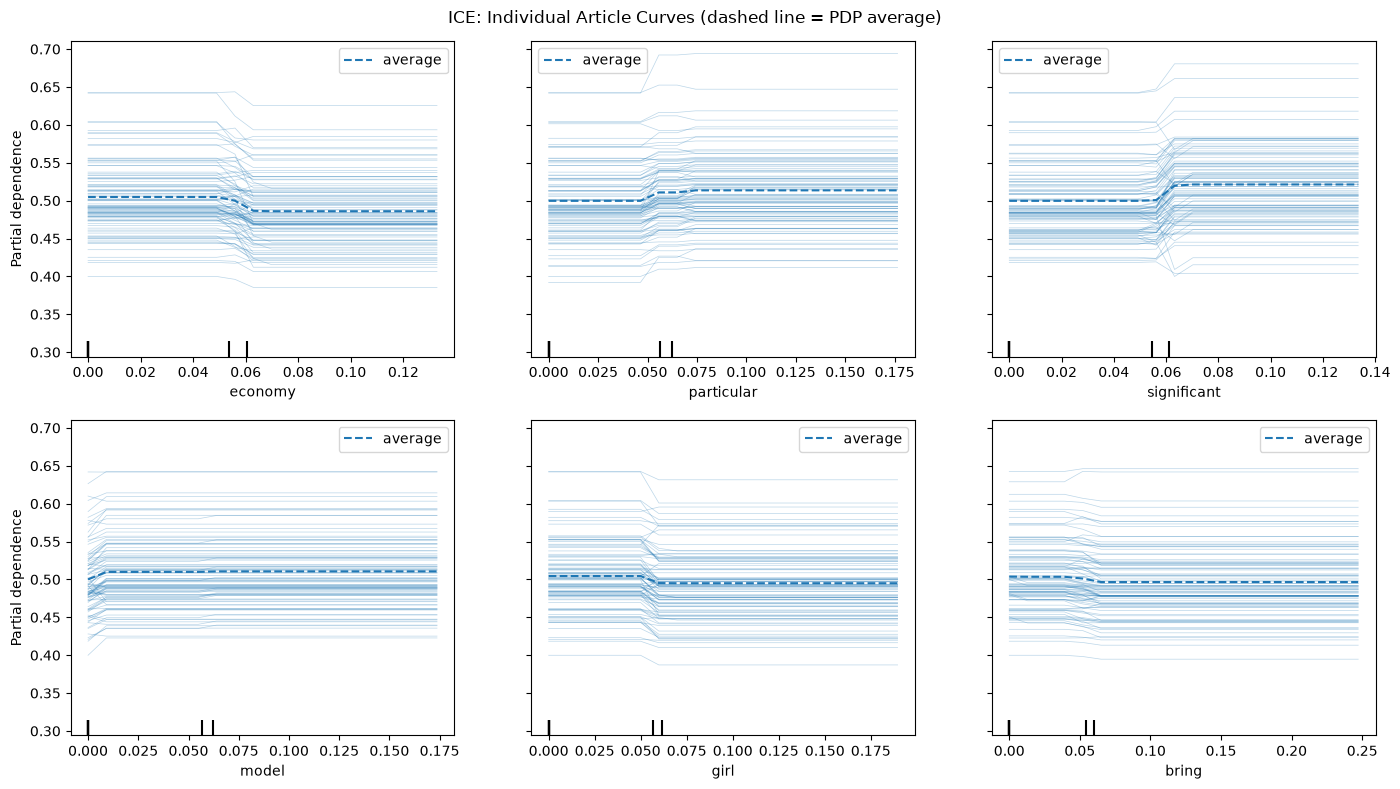

In [20]:
ice_display = PartialDependenceDisplay.from_estimator(
    lgbm, X_sample,
    features=pdp_idx,
    feature_names=list(feature_names),
    kind="both",
    subsample=100,
    grid_resolution=20,
    percentiles=(0, 1),
    n_cols=3,
    random_state=RANDOM_STATE,
)
ice_display.figure_.set_size_inches(14, 8)
ice_display.figure_.suptitle("ICE: Individual Article Curves (dashed line = PDP average)")
plt.tight_layout()
plt.show()

Each thin line is one of 100 articles, and the dashed line is the PDP average. The lines start anywhere from about 0.40 to 0.65, because each prediction also depends on the article's other words. The average looks flat only because the vertical axis is about ten times wider than in the PDP.

At the step, most lines move the same way as the average, but by very different amounts, from nothing to about 5 percentage points. A few move the other way: for significant, one line drops when the word is added. So the PDP shows the typical effect, but its size, and sometimes its direction, depends on the other words in the article.

## 12. Individual Decisions (LIME and SHAP)

So far we have looked at what drives the model overall. Now we look at single articles. First, SP-LIME picks a small set of representative articles. Then we look at three cases chosen by outcome: the fake article the model was most confident about, the fake article it missed most clearly, and the real article it most confidently flagged as fake.

In [21]:
from IPython.display import display

explainer_lime = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)

def predict_proba_text(texts):
    return lgbm.predict_proba(tfidf.transform(texts))

test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true_arr = y_test.reset_index(drop=True).to_numpy()
y_pred_arr = np.asarray(y_pred)
proba_fake = lgbm.predict_proba(X_test)[:, 1]

tp = np.where((y_true_arr == 1) & (y_pred_arr == 1))[0]
fn = np.where((y_true_arr == 1) & (y_pred_arr == 0))[0]
fp = np.where((y_true_arr == 0) & (y_pred_arr == 1))[0]

cases = {
    "True Positive (fake, caught)":      tp[np.argmax(proba_fake[tp])],
    "False Negative (fake, missed)":     fn[np.argmin(proba_fake[fn])],
    "False Positive (real, flagged)":    fp[np.argmax(proba_fake[fp])],
}

### 12.1 SP-LIME: Choosing Representative Articles

Instead of picking articles by hand, SP-LIME (submodular pick) explains 200 random test articles and picks the 5 whose explanations together cover the most words with the least repetition. It does not look at the label or category, so we check those afterwards.

In [22]:
from lime.submodular_pick import SubmodularPick

N_CANDIDATES = 200
N_PICKS = 5

rng_sp = np.random.RandomState(RANDOM_STATE)
cand_idx = rng_sp.choice(len(test_text), size=N_CANDIDATES, replace=False)
cand_text = test_text.iloc[cand_idx].tolist()

sp = SubmodularPick(
    explainer_lime, cand_text, predict_proba_text,
    method="full",
    num_exps_desired=N_PICKS,
    num_features=7,
    num_samples=1000,
    top_labels=None         
)
sp_idx = cand_idx[sp.V]   

In [23]:
def outcome(i):
    t, p = int(y_true_arr[i]), int(y_pred_arr[i])
    return {(1, 1): "TP (fake, caught)", (1, 0): "FN (fake, missed)",
            (0, 1): "FP (real, flagged)", (0, 0): "TN (real, correct)"}[(t, p)]

sp_table = pd.DataFrame({
    "category": [df.loc[y_test.index[i], "category"] for i in sp_idx],
    "true_label": ["fake" if y_true_arr[i] == 1 else "real" for i in sp_idx],
    "P(fake)": [round(float(proba_fake[i]), 3) for i in sp_idx],
    "outcome": [outcome(i) for i in sp_idx],
})
display(sp_table)

words = lambda e: {w for w, _ in e.as_list(label=1)}
picked_words = set().union(*[words(e) for e in sp.sp_explanations])
all_words = set().union(*[words(e) for e in sp.explanations])

,category,true_label,P(fake),outcome
0,Health,real,0.520,"FP (real, flagged)"
1,Entertainment,fake,0.479,"FN (fake, missed)"
2,Technology,fake,0.460,"FN (fake, missed)"
3,Entertainment,real,0.570,"FP (real, flagged)"
4,Science,real,0.406,"TN (real, correct)"


SP-LIME pick 1 | P(fake) = 0.520


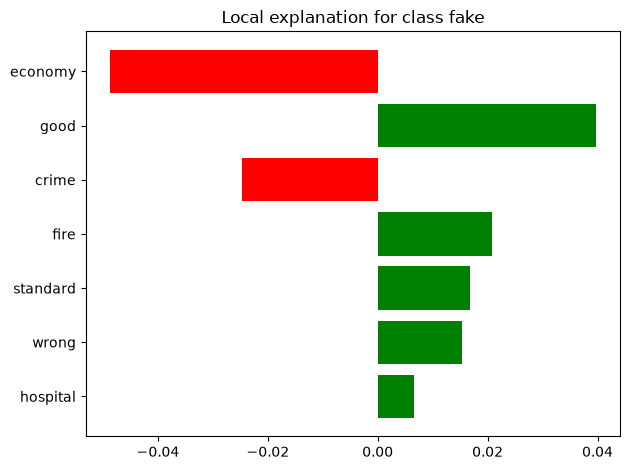

SP-LIME pick 2 | P(fake) = 0.479


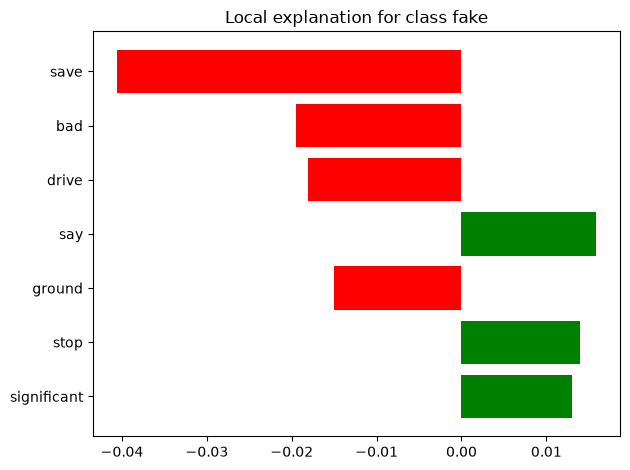

SP-LIME pick 3 | P(fake) = 0.460


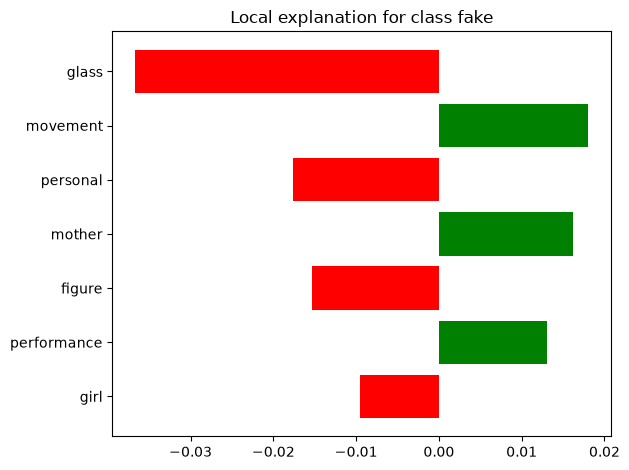

SP-LIME pick 4 | P(fake) = 0.570


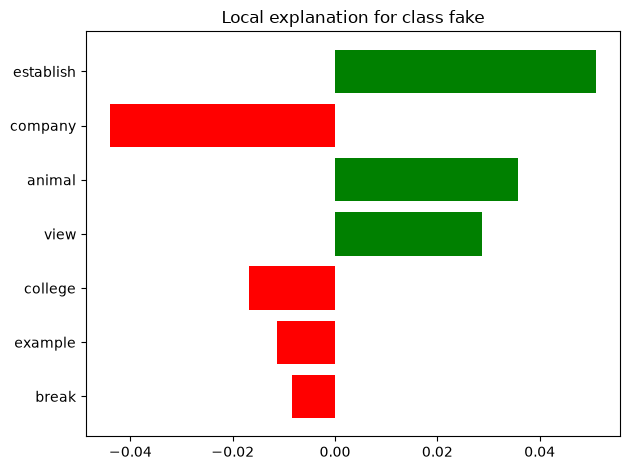

SP-LIME pick 5 | P(fake) = 0.406


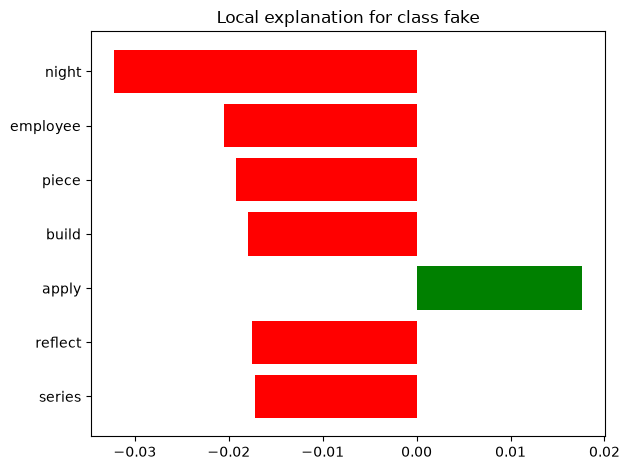

In [24]:
for rank, (exp, i) in enumerate(zip(sp.sp_explanations, sp_idx), start=1):
    print(f"SP-LIME pick {rank} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

The five picks come from four categories, but the mix is chance, since SP-LIME only looks at words. All five scores are between 0.406 and 0.570, so the model was unsure about every one.

**Wrongly flagged real articles (picks 1 and 4).** The words pushing toward fake outweigh those pushing toward real. In pick 1, good, fire, standard, wrong and hospital (about 0.10 in total) beat economy and crime (about 0.07). In pick 4, establish, animal and view (about 0.12) beat company, college, example and break (about 0.08).

**Missed fake articles (picks 2 and 3).** The opposite happens. In pick 2, save, bad, drive and ground pull toward real (about 0.09), outweighing say, stop and significant (about 0.04). In pick 3, glass, personal, figure and girl (about 0.08) outweigh movement, mother and performance (about 0.05).

**Correct real article (pick 5).** This is the most one-sided: six words, led by night, push toward real, and only apply pushes toward fake.

No word appears in more than one pick. The six that also appear in the global SHAP results (economy, good, significant, stop, girl, animal) all push the same way as there. The rest are ordinary words that appear in no global result.

### 12.2 LIME: Three Cases by Outcome

LIME removes words from one article and watches how the predicted probability changes. Positive weights push toward fake, negative toward real.

True Positive (fake, caught) | P(fake) = 0.690


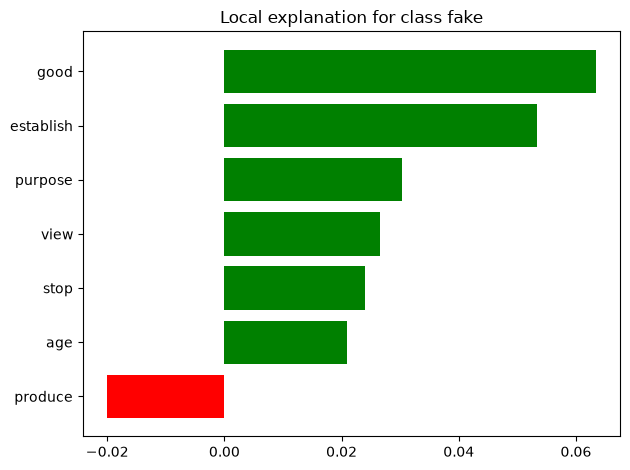

False Negative (fake, missed) | P(fake) = 0.312


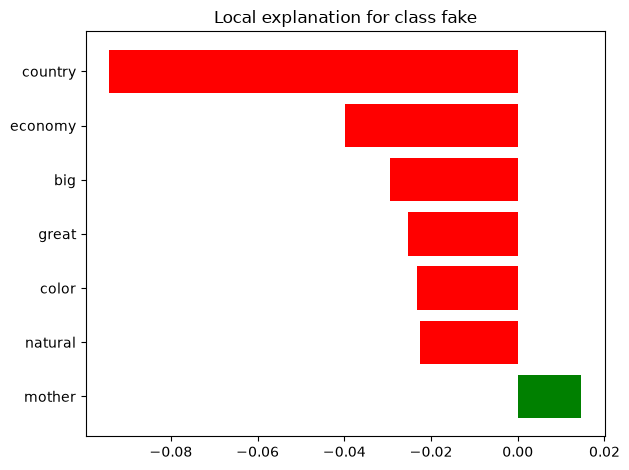

False Positive (real, flagged) | P(fake) = 0.717


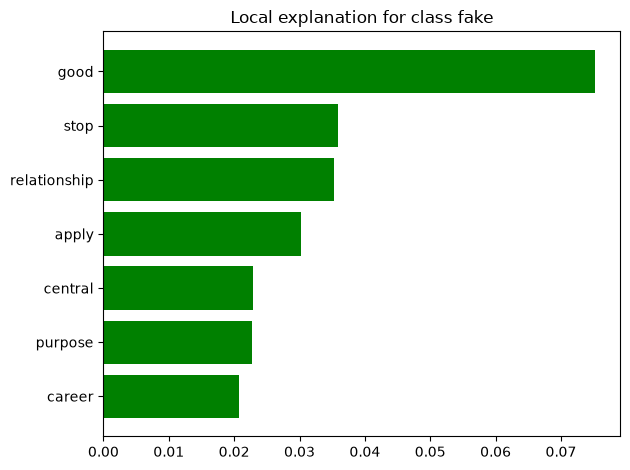

In [25]:
for name, i in cases.items():
    exp = explainer_lime.explain_instance(
        test_text.iloc[i], predict_proba_text,
        num_features=7, num_samples=1000, labels=(1,)
    )
    print(f"{name} | P(fake) = {proba_fake[i]:.3f}")
    exp.as_pyplot_figure(label=1)
    plt.tight_layout()
    plt.show()

These are the most extreme articles in each group.

**True Positive (P(fake) = 0.690).** good (0.063) and establish (0.053) push hardest toward fake, followed by purpose, view, stop and age. Only produce pushes toward real (0.020).

**False Negative (P(fake) = 0.312).** country pulls toward real by 0.094, the largest bar in all three cases. economy, big, great, color and natural add to it, and only mother pushes toward fake. None of these words says anything about whether the reporting is trustworthy.

**False Positive (P(fake) = 0.717).** All seven words push toward fake, led by good (0.075) and stop (0.036). This is the highest probability of fake in the whole test set, and it belongs to a real article.

The flagged real article and the caught fake one share good, stop and purpose, so the model gives the same reasons for both. Its most confident fake call is a real article, so higher confidence does not mean a more reliable answer.

### 12.3 SHAP Waterfall (the missed fake article)

LIME approximates the model around one article, while SHAP splits the model's own output into exact contributions. Here SHAP explains the missed fake article from 12.2, so the two methods can be compared on the same case. Values are in log-odds.

c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


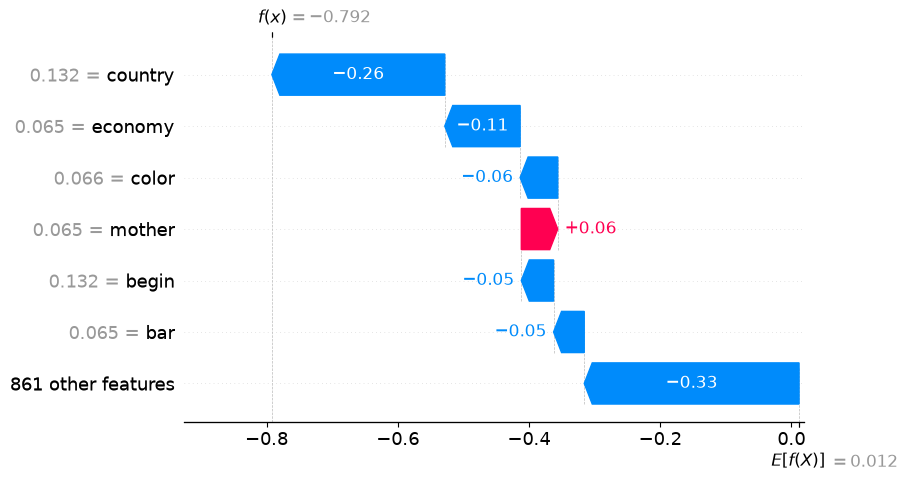

In [26]:
fn_idx = cases["False Negative (fake, missed)"]
x_fn = X_test_dense[fn_idx:fn_idx + 1]

sv_fn = explainer_shap.shap_values(x_fn, check_additivity=False)
if isinstance(sv_fn, list):
    sv_fn_fake = sv_fn[1]
elif sv_fn.ndim == 3:
    sv_fn_fake = sv_fn[:, :, 1]
else:
    sv_fn_fake = sv_fn

shap.plots.waterfall(
    shap.Explanation(
        values=sv_fn_fake[0], base_values=base_value,
        data=x_fn[0], feature_names=list(feature_names)
    ),
    max_display=7
)

The waterfall starts at 0.012 log-odds, the model's average output (a probability of about 0.503), and ends at −0.792 (a probability of 0.312) for this missed fake article.

country is the largest single term, at −0.26 log-odds (about 6 percentage points), followed by economy (−0.11). color, begin and bar push a little further toward real, and mother is the only term pushing toward fake (+0.06). The 861 other terms together add −0.33, so many small terms matter more in total than any single one.

SHAP and LIME agree closely. Both put country first and economy second, and both show color toward real and mother as the only push toward fake. So for this article, LIME gives a reliable picture of what drives the prediction.

## 13. Summary

LightGBM catches 52% of fake articles (recall 0.5191), with an accuracy of 0.509 and a ROC AUC of 0.516, so it barely separates fake from real. Its recall is about the same as the Logistic Regression baseline (0.5167) and roughly equal to the 51% of articles it labels as fake. Training recall (0.7768) is much higher than test recall, so it still memorizes part of the training data.

The explanation methods agree that no word matters much:
- **PFI:** shuffling any top term changes recall by at most 0.005. This is small, but larger than for any random term, so these effects are real.
- **TreeSHAP:** the top term, significant, moves the output by about 0.6 percentage points on average.
- **PDP and ICE:** each term shifts the average probability by at most 2 points, though single articles can move up to 5 points, mostly in the same direction.
- **LIME:** predictions come from several ordinary words, and the model's most confident fake call is a real article.
- **SHAP waterfall:** for the missed fake article, SHAP and LIME agree on the main words, country first and economy second.

Where SHAP, PDP, LIME and the baseline share a term, they agree on its direction: significant, good, particular and stop lean toward fake, and economy and girl toward real. PFI picks different terms (radio, painting), because it measures the effect on catching fake articles rather than the average effect on the output.

Overall, LightGBM does no better than the baseline, which suggests the text carries very little signal. All results come from one train/test split, so small differences between models should not be over-read.